<a href="https://colab.research.google.com/github/FattahulAlim/Machine_Learning_Sem5/blob/main/JS13/Praktikum3_244107020018_MFattahulAlim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

In [2]:
# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100)

# Evaluasi
print("Prediksi:", model.predict(X_test))

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 797ms/step - loss: 0.1506
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.1480
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.1455
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.1430
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.1405
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.1381
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.1357
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.1333
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.1309
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.1286
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.1263
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.1240
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.1218
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.1195
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.1173
Epoch 16/100
1/1 ━━━━━━━━━━━━━

# Tugas 4

In [3]:
def latih_lr(lr, epochs=100):
    tf.keras.utils.set_random_seed(42)  # bobot awal sama
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    hist = model.fit(X_train, y_train, epochs=epochs, verbose=0)
    loss_train = hist.history['loss'][-1]
    loss_test = model.evaluate(X_test, y_test, verbose=0)
    return loss_train, loss_test

print(f"{'Learning Rate':<15}{'Loss Train':<15}{'Loss Test'}")
print("-" * 40)
for lr in [0.0001, 0.001, 0.01, 0.1]:
    loss_train, loss_test = latih_lr(lr)
    print(f"{lr:<15}{loss_train:<15.6f}{loss_test:.6f}")

Learning Rate  Loss Train     Loss Test
----------------------------------------
0.0001         1.163206       0.209237
0.001          0.730216       0.005318
0.01           0.001296       0.069257
0.1            0.000001       0.000203


## Perbandingan Learning Rate pada Model Regresi (Optimizer Adam)

### 1. Hasil Loss

| Learning Rate | Loss Train | Loss Test |
|---------------|------------|-----------|
| 0.0001        | 1.163206   | 0.209237  |
| 0.001 (default) | 0.730216 | 0.005318  |
| 0.01          | 0.001296   | 0.069257  |
| 0.1           | 0.000001   | 0.000203  |

### 2. Analisis

- **Loss train:** Semakin besar learning rate, loss train semakin kecil. Pada learning rate 0.0001 dan 0.001, loss train masih tinggi (1.1632 dan 0.7302) karena model belajar terlalu lambat dan jumlah update bobot dalam 100 epoch belum cukup. Pada learning rate 0.01 loss turun drastis menjadi 0.0013, dan pada 0.1 menjadi sekitar 0.000001.
- **Loss test:** Loss test terkecil didapat pada learning rate 0.1 (0.000203). Loss test pada learning rate 0.001 (0.0053) lebih kecil daripada 0.01 (0.0693), padahal loss train-nya jauh lebih besar. Hal ini kemungkinan kebetulan karena data test hanya 1 sampel, sehingga loss test kurang dapat diandalkan.
- **Kesimpulan:** Pada percobaan ini, learning rate 0.1 memberikan hasil terbaik, yaitu loss train dan loss test paling kecil. Learning rate yang terlalu kecil membuat model belajar lambat (belum konvergen dalam 100 epoch). Namun ini tidak dapat dijadikan acuan mutlak karena data yang digunakan sangat sederhana dan kecil (5 baris), sehingga learning rate besar masih aman. Pada data yang lebih kompleks, learning rate yang terlalu besar bisa membuat training tidak stabil.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


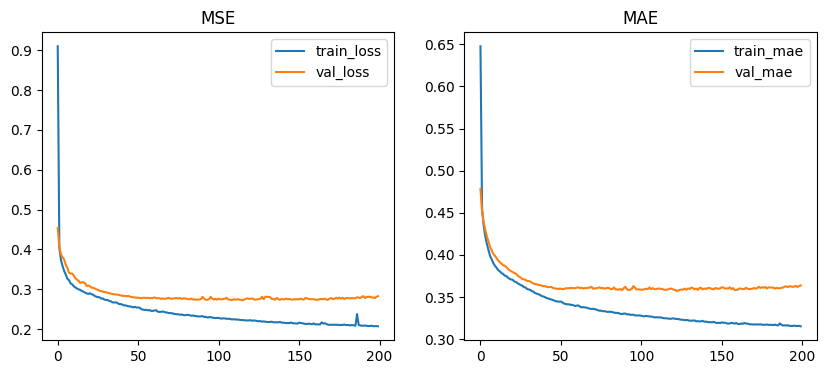

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
RMSE: 0.5318386184621007


In [5]:
# MLP regresi (Keras)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam


# 1. Load
data = fetch_california_housing()
X = data.data; y = data.target

# Note: Dataset housing boston diganti dengan alternatif lain yaitu california housing
# Hal ini diakibatkan oleh dataset boston yang telah dihapus akibat masalah etis
# tentang dugaan kandungan masalah yang menyinggu SARA pada salah satu variabelnya

# 2. Preprocess
scaler = StandardScaler(); Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

# 3. Build model
model = Sequential([
Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
Dense(32, activation='relu'),
Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

from sklearn.metrics import mean_squared_error
pred = model.predict(X_val)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))